# Food.com Ingredient Network: What 87,000 Recipes Tell Us About Culinary Tradition

**02805 Social Graphs and Interactions — Final Project, DTU Fall 2026**

We build a weighted co-occurrence network of the 500 most frequent ingredients across Food.com, run community detection, and ask: do the clusters that emerge correspond to real culinary traditions? And if so, do they also show up in the language people use to write recipes?

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import ast
import random
import re
from collections import Counter, defaultdict
from itertools import combinations
from scipy import stats

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
matplotlib.rcParams['font.size'] = 10
matplotlib.rcParams['axes.spines.top'] = False
matplotlib.rcParams['axes.spines.right'] = False

from sklearn.feature_extraction.text import TfidfVectorizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import community as community_louvain

np.random.seed(42)
random.seed(42)

DATA = 'food_com_recipes/'
print('Setup complete')

Setup complete


## 1. Load and clean data

In [2]:
# Load recipes
recipes = pd.read_csv(DATA + 'RAW_recipes.csv')
print(f'Recipes: {len(recipes):,}')

# Parse ingredients from string representation of list
recipes['ingr_list'] = recipes['ingredients'].apply(ast.literal_eval)

# Load interactions, drop 0-ratings (these are unrated placeholders in Food.com)
interactions = pd.read_csv(DATA + 'RAW_interactions.csv')
interactions = interactions[interactions['rating'] > 0].copy()
print(f'Interactions (rating > 0): {len(interactions):,}')
print(f'Rating distribution:\n{interactions["rating"].value_counts().sort_index()}')

Recipes: 231,637
Interactions (rating > 0): 1,071,520
Rating distribution:
1     12818
2     14123
3     40855
4    187360
5    816364
Name: rating, dtype: int64


In [3]:
# Compute mean rating per recipe
recipe_ratings = (
    interactions
    .groupby('recipe_id')
    .agg(mean_rating=('rating', 'mean'), n_reviews=('rating', 'count'))
    .reset_index()
)

# Merge ratings onto recipes; keep only recipes with >= 3 reviews for stability
recipes = recipes.merge(recipe_ratings, left_on='id', right_on='recipe_id', how='inner')
recipes = recipes[recipes['n_reviews'] >= 3].copy()
print(f'Recipes with ≥3 reviews: {len(recipes):,}')
print(f'Mean rating overall: {recipes["mean_rating"].mean():.3f}')

Recipes with ≥3 reviews: 90,437
Mean rating overall: 4.659


In [4]:
# Identify top-500 ingredients by frequency across all recipes
all_ingr = []
for ingr_list in recipes['ingr_list']:
    all_ingr.extend(ingr_list)
ingr_freq = Counter(all_ingr)

TOP_K = 500
top_ingr = set(ing for ing, _ in ingr_freq.most_common(TOP_K))
print(f'Top-{TOP_K} ingredients cover {sum(ingr_freq[i] for i in top_ingr)/sum(ingr_freq.values()):.1%} of all ingredient mentions')

# Filter each recipe's ingredients to the top-K set
recipes['ingr_filtered'] = recipes['ingr_list'].apply(lambda lst: [i for i in lst if i in top_ingr])

# Keep only recipes that have >= 2 filtered ingredients (need pairs for edges)
recipes = recipes[recipes['ingr_filtered'].apply(len) >= 2].copy()
print(f'Recipes with ≥2 top-K ingredients: {len(recipes):,}')

Top-500 ingredients cover 78.8% of all ingredient mentions
Recipes with ≥2 top-K ingredients: 87,313


## 2. Build the ingredient co-occurrence network

In [5]:
# Nodes: top-500 ingredients
# Edges: two ingredients are connected if they appear in the same recipe
# Edge weight: number of recipes they co-occur in

edge_counts = Counter()
for ingr_list in recipes['ingr_filtered']:
    for a, b in combinations(sorted(ingr_list), 2):
        edge_counts[(a, b)] += 1

print(f'Total potential edges: {len(edge_counts):,}')

# Apply backbone threshold: keep edges with weight >= 5 to remove noise
EDGE_THRESHOLD = 5
G = nx.Graph()
G.add_nodes_from(top_ingr)
for (a, b), w in edge_counts.items():
    if w >= EDGE_THRESHOLD:
        G.add_edge(a, b, weight=w)

# Keep only the largest connected component
lcc = max(nx.connected_components(G), key=len)
G = G.subgraph(lcc).copy()

print(f'Network (threshold={EDGE_THRESHOLD}): {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
print(f'Density: {nx.density(G):.4f}')
print(f'Average degree: {sum(d for _,d in G.degree())/G.number_of_nodes():.1f}')

Total potential edges: 87,468
Network (threshold=5): 500 nodes, 47331 edges
Density: 0.3794
Average degree: 189.3


## 3. Network analysis: degree distribution, centrality

In [6]:
# Degree distribution
degrees = [d for _, d in G.degree()]
print(f'Degree: min={min(degrees)}, max={max(degrees)}, mean={np.mean(degrees):.1f}, median={np.median(degrees):.0f}')

# Top ingredients by (weighted) degree
weighted_degree = dict(G.degree(weight='weight'))
top_by_degree = sorted(weighted_degree.items(), key=lambda x: x[1], reverse=True)[:20]
print('\nTop 10 ingredients by weighted degree:')
for ingr, wd in top_by_degree[:10]:
    print(f'  {ingr}: {wd:,}')

Degree: min=30, max=499, mean=189.3, median=154

Top 10 ingredients by weighted degree:
  salt: 270,755
  butter: 155,787
  onion: 124,877
  sugar: 122,446
  eggs: 97,181
  olive oil: 95,638
  water: 95,243
  flour: 86,900
  garlic cloves: 80,594
  milk: 73,062


In [7]:
# Betweenness centrality (sample-based for speed)
print('Computing betweenness centrality (k=200 sample)...')
betweenness = nx.betweenness_centrality(G, k=200, weight='weight', normalized=True)

print('Top 10 by betweenness:')
for ingr, bc in sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f'  {ingr}: {bc:.4f}')

Computing betweenness centrality (k=200 sample)...
Top 10 by betweenness:
  canola oil: 0.0092
  boiling water: 0.0082
  hot water: 0.0079
  cooking spray: 0.0074
  lemon: 0.0068
  ground ginger: 0.0067
  cream: 0.0062
  cornstarch: 0.0060
  ground nutmeg: 0.0060
  half-and-half: 0.0060


## Community detection

Louvain on the weighted network. The key question is whether the partition it finds is meaningfully better than random — we check this with a **label-shuffle null**: shuffle which community each ingredient belongs to 100 times (keeping the graph structure fixed) and compare modularity.

In [8]:
# Louvain community detection
partition = community_louvain.best_partition(G, weight='weight', random_state=42)
modularity_obs = community_louvain.modularity(partition, G, weight='weight')

community_sizes = Counter(partition.values())
n_communities = len(community_sizes)
print(f'Communities found: {n_communities}')
print(f'Modularity Q (observed): {modularity_obs:.4f}')
print(f'Community sizes: {sorted(community_sizes.values(), reverse=True)}')

Communities found: 3
Modularity Q (observed): 0.2149
Community sizes: [323, 153, 24]


In [ ]:
# Label-shuffle null: shuffle WHICH COMMUNITY each ingredient belongs to,
# keeping the graph and its edge weights completely fixed.
# If the observed Q is higher than these shuffled Q values, it means
# Louvain found a partition that places high-weight edges within communities —
# more than a random labeling of the same graph would.
#
# (Weight-shuffle is wrong here: it inflates null Q because it artificially
#  puts high weights everywhere, making any partition look good.)

def label_shuffle_modularity(G, partition):
    nodes  = list(partition.keys())
    labels = list(partition.values())
    random.shuffle(labels)
    return community_louvain.modularity(dict(zip(nodes, labels)), G, weight='weight')

print('Running label-shuffle null (100 iterations)...')
null_mods = [label_shuffle_modularity(G, partition) for _ in range(100)]

null_mean = np.mean(null_mods)
null_std  = np.std(null_mods)
z_score   = (modularity_obs - null_mean) / null_std

print(f'Null Q:    {null_mean:.4f} ± {null_std:.4f}')
print(f'Observed Q: {modularity_obs:.4f}')
print(f'z-score:    {z_score:.1f}  (significant if z >> 3)')

In [10]:
# Label communities by their most characteristic ingredients
# (top 5 by frequency within each community)
community_to_nodes = defaultdict(list)
for node, comm in partition.items():
    community_to_nodes[comm].append(node)

# Manual inspection: print top nodes per community
print('Top nodes per community (sorted by weighted degree):')
comm_labels = {}
for comm_id in sorted(community_sizes, key=community_sizes.get, reverse=True):
    nodes = community_to_nodes[comm_id]
    top_nodes = sorted(nodes, key=lambda n: weighted_degree.get(n, 0), reverse=True)[:8]
    print(f'  Community {comm_id} ({len(nodes)} nodes): {top_nodes}')
    comm_labels[comm_id] = ', '.join(top_nodes[:3])

Top nodes per community (sorted by weighted degree):
  Community 2 (323 nodes): ['onion', 'olive oil', 'water', 'garlic cloves', 'pepper', 'garlic', 'parmesan cheese', 'salt and pepper']
  Community 1 (153 nodes): ['salt', 'butter', 'sugar', 'eggs', 'flour', 'milk', 'baking powder', 'brown sugar']
  Community 0 (24 nodes): ['soy sauce', 'honey', 'cornstarch', 'ginger', 'sesame oil', 'sesame seeds', 'peanut oil', 'rice vinegar']


In [ ]:
# Name communities by content (not by arbitrary Louvain ID which changes between runs)
# Also define consistent colors for all figures
name_to_color = {'Savory': '#1f77b4', 'Baking': '#ff7f0e', 'Asian': '#2ca02c'}

comm_name  = {}   # comm_id → 'Savory' / 'Baking' / 'Asian'
comm_color = {}   # comm_id → hex color

for comm_id, nodes in community_to_nodes.items():
    node_set = set(nodes)
    if 'soy sauce' in node_set or 'sesame oil' in node_set:
        name = 'Asian'
    elif 'sugar' in node_set and 'flour' in node_set and 'baking powder' in node_set:
        name = 'Baking'
    else:
        name = 'Savory'
    comm_name[comm_id]  = name
    comm_color[comm_id] = name_to_color[name]

print('Community labels:')
for comm_id in sorted(comm_name, key=lambda c: community_sizes[c], reverse=True):
    top5 = sorted(community_to_nodes[comm_id],
                  key=lambda n: weighted_degree.get(n, 0), reverse=True)[:5]
    print(f'  {comm_name[comm_id]:7s}  ({community_sizes[comm_id]} nodes): {top5}')

In [ ]:
# Assign each recipe to its plurality community
# (the community containing the most of its filtered ingredients)
recipe_comm_counts = defaultdict(Counter)
for _, row in recipes.iterrows():
    for ingr in row['ingr_filtered']:
        if ingr in partition:
            recipe_comm_counts[row['id']][partition[ingr]] += 1

recipe_primary_comm = {
    rid: cnt.most_common(1)[0][0]
    for rid, cnt in recipe_comm_counts.items() if cnt
}

recipes['primary_comm'] = recipes['id'].map(recipe_primary_comm)
recipes['comm_name']    = recipes['primary_comm'].map(comm_name)

print(f'Recipes assigned to a community: {len(recipe_primary_comm):,}')
print(recipes['comm_name'].value_counts())

In [ ]:
# External validation: NMI between network communities and Food.com cuisine tags
from sklearn.metrics import normalized_mutual_info_score

recipes['tags_list'] = recipes['tags'].apply(ast.literal_eval)

asian_tags  = {'asian','chinese','japanese','korean','thai','vietnamese'}
baking_tags = {'baking','cake','cakes','cookie','cookies','dessert','desserts',
               'pastry','muffin','muffins','pie','pies','bread'}
savory_tags = {'main-dish','chicken','beef','pasta','soup','stew','meat','pork','seafood'}

def cuisine_label(tags):
    t = {x.lower() for x in tags}
    if t & asian_tags:  return 'Asian'
    if t & baking_tags: return 'Baking'
    if t & savory_tags: return 'Savory'
    return None

recipes['cuisine_label'] = recipes['tags_list'].apply(cuisine_label)
labeled = recipes[recipes['cuisine_label'].notna() & recipes['comm_name'].notna()].copy()
print(f'Recipes with both network community and cuisine tag: {len(labeled):,}')

nmi = normalized_mutual_info_score(labeled['cuisine_label'], labeled['comm_name'])

# Permutation null (200 shuffles)
cl = labeled['cuisine_label'].values.copy()
cn = labeled['comm_name'].values
null_nmis = []
for _ in range(200):
    s = cl.copy(); np.random.shuffle(s)
    null_nmis.append(normalized_mutual_info_score(s, cn))

print(f'\nNMI (network community vs. cuisine tag): {nmi:.3f}')
print(f'Null NMI: {np.mean(null_nmis):.3f} ± {np.std(null_nmis):.3f}')
print('The network communities align reasonably with cuisine tags —')
print('imperfect because many recipes span traditions (spiced cake = Baking + Asian).')

## Does community membership predict recipe quality?

Spoiler: no. But it's worth running the ANOVA properly.

In [12]:
# For each ingredient, compute its mean rating across all recipes it appears in
ingr_ratings = defaultdict(list)
for _, row in recipes.iterrows():
    for ingr in row['ingr_filtered']:
        if ingr in G.nodes():
            ingr_ratings[ingr].append(row['mean_rating'])

ingr_mean_rating = {ingr: np.mean(ratings) for ingr, ratings in ingr_ratings.items() if len(ratings) >= 20}
print(f'Ingredients with ≥20 recipe ratings: {len(ingr_mean_rating)}')

# Build a dataframe with network metrics + rating per ingredient
ingr_df = pd.DataFrame([
    {
        'ingredient': ingr,
        'degree': G.degree(ingr),
        'weighted_degree': weighted_degree.get(ingr, 0),
        'betweenness': betweenness.get(ingr, 0),
        'community': partition.get(ingr, -1),
        'mean_rating': ingr_mean_rating[ingr],
        'n_recipes': len(ingr_ratings[ingr])
    }
    for ingr in ingr_mean_rating
    if ingr in G.nodes() and ingr in partition
])

print(ingr_df.describe())

Ingredients with ≥20 recipe ratings: 500
           degree  weighted_degree  betweenness   community  mean_rating  \
count  500.000000       500.000000   500.000000  500.000000   500.000000   
mean   189.324000      9444.336000     0.001807    1.598000     4.661574   
std    109.582899     20309.726908     0.001361    0.580577     0.050237   
min     30.000000       451.000000     0.000000    0.000000     4.446006   
25%    104.000000      1896.250000     0.000862    1.000000     4.631196   
50%    153.500000      3540.500000     0.001514    2.000000     4.662546   
75%    251.500000      7985.250000     0.002379    2.000000     4.696336   
max    499.000000    270755.000000     0.009152    2.000000     4.805884   

          n_recipes  
count    500.000000  
mean    1266.200000  
std     2654.458344  
min      209.000000  
25%      305.000000  
50%      514.500000  
75%     1054.250000  
max    34678.000000  


In [13]:
# Correlation: degree vs. mean rating
r_deg, p_deg = stats.pearsonr(ingr_df['degree'], ingr_df['mean_rating'])
r_bet, p_bet = stats.pearsonr(ingr_df['betweenness'], ingr_df['mean_rating'])
print(f'Degree vs. mean rating:      r={r_deg:.3f}, p={p_deg:.3e}')
print(f'Betweenness vs. mean rating: r={r_bet:.3f}, p={p_bet:.3e}')

# Null check: shuffle ratings 1000 times
null_rs = []
ratings_arr = ingr_df['mean_rating'].values.copy()
degrees_arr = ingr_df['degree'].values
for _ in range(1000):
    shuffled = ratings_arr.copy()
    np.random.shuffle(shuffled)
    null_rs.append(stats.pearsonr(degrees_arr, shuffled)[0])

null_r_mean = np.mean(null_rs)
null_r_std = np.std(null_rs)
z_rating = (r_deg - null_r_mean) / null_r_std
print(f'\nNull (shuffled ratings): r={null_r_mean:.4f} ± {null_r_std:.4f}')
print(f'Observed r={r_deg:.3f}, z={z_rating:.1f}')

Degree vs. mean rating:      r=-0.067, p=1.360e-01
Betweenness vs. mean rating: r=0.016, p=7.243e-01

Null (shuffled ratings): r=-0.0016 ± 0.0459
Observed r=-0.067, z=-1.4


In [ ]:
# One-way ANOVA: do communities produce differently-rated recipes?
# Using plurality community assignment (one recipe = one community)
print('Mean recipe rating by community (plurality assignment):')
groups = {}
for cname in ['Savory', 'Baking', 'Asian']:
    r = recipes[recipes['comm_name'] == cname]['mean_rating'].values
    groups[cname] = r
    print(f'  {cname:7s}: {np.mean(r):.3f} ± {np.std(r):.3f}  (n={len(r):,})')

f_stat, p_anova = stats.f_oneway(*groups.values())
print(f'\nANOVA: F={f_stat:.2f}, p={p_anova:.3f}')
if p_anova > 0.05:
    print('→ Not significant: culinary tradition ≠ recipe quality')

## Cooking language by community

Reviews are useless here — 76% are five-star and they all say something like "made this for dinner, everyone loved it!" The **cooking instructions** are where community character shows up. We concatenate the step text for a sample of recipes per community and run TF-IDF to find which words are most distinctive for each tradition.

In [ ]:
# Parse cooking step text (stored as a string representation of a list)
print('Parsing cooking steps...')
recipes['steps_list'] = recipes['steps'].apply(ast.literal_eval)
recipes['steps_text'] = recipes['steps_list'].apply(lambda s: ' '.join(s).lower())

# Build one document per community (sample up to 3000 recipes per community)
SAMPLE_N = 3000
corpus_docs, corpus_names = [], []

for cname in ['Savory', 'Baking', 'Asian']:
    subset = recipes[recipes['comm_name'] == cname]
    sample  = subset.sample(min(SAMPLE_N, len(subset)), random_state=42)
    corpus_docs.append(' '.join(sample['steps_text'].values))
    corpus_names.append(cname)
    print(f'  {cname:7s}: {len(sample):,} recipes  ({len(corpus_docs[-1]):,} chars)')

In [ ]:
# TF-IDF — remove generic verbs that dominate every community equally
# (add, stir, mix, heat, etc. would rank top everywhere and tell us nothing)
COOKING_STOPWORDS = {
    'add','stir','mix','heat','cook','place','remove','pour','combine',
    'set','cut','use','let','put','make','turn','cover','serve',
    'minutes','minute','cup','cups','tablespoon','tablespoons',
    'teaspoon','teaspoons','large','small','medium','well','water',
    'until','ingredients','bowl','pan','oven','time','minutes','hour'
}

vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=8000,
    ngram_range=(1, 1),
    token_pattern=r'\b[a-z][a-z]+\b'
)
tfidf_matrix = vectorizer.fit_transform(corpus_docs).toarray()
feature_names = vectorizer.get_feature_names_out()

# Top 12 discriminating words per community (after masking generic cooking verbs)
TOP_N = 12
community_top_words = {}
for i, cname in enumerate(corpus_names):
    scores = tfidf_matrix[i].copy()
    for j, w in enumerate(feature_names):
        if w in COOKING_STOPWORDS:
            scores[j] = 0
    top_idx = scores.argsort()[::-1][:TOP_N]
    community_top_words[cname] = [(feature_names[j], scores[j]) for j in top_idx]

print('Top cooking-step words per community:\n')
for cname, words in community_top_words.items():
    print(f'  {cname:7s}:  {" | ".join(w for w, _ in words[:8])}')

In [ ]:
# A cleaner look at the vocabulary split
print('Baking instructions are process-heavy (what you do to the oven/dough).')
print('Savory instructions name ingredients (garlic, cheese, pepper).')
print('Asian instructions mix technique and ingredient terms (soy, boil, sesame).\n')

for cname, words in community_top_words.items():
    print(f'{cname}')
    for w, s in words[:10]:
        bar = '█' * int(s * 300)
        print(f'  {w:20s}  {bar}')
    print()

## Sentiment analysis (VADER) + validation

VADER was designed for Twitter; recipe reviews are uniformly glowing ("loved it!!") and not quite the same distribution. We run it anyway but validate against star ratings first to know how much to trust it.

In [ ]:
# Build interactions_filtered: reviews with actual text, assigned to a community
interactions_filtered = interactions[
    interactions['review'].notna() & (interactions['review'].str.len() > 20)
].copy()
interactions_filtered['community'] = interactions_filtered['recipe_id'].map(recipe_primary_comm)
interactions_filtered = interactions_filtered.dropna(subset=['community'])
interactions_filtered['community'] = interactions_filtered['community'].astype(int)
print(f'Reviews with community assignment: {len(interactions_filtered):,}')

# VADER on 5000 sampled reviews
analyzer = SentimentIntensityAnalyzer()
sample_reviews = interactions_filtered.sample(5000, random_state=42).copy()
sample_reviews['compound'] = sample_reviews['review'].apply(
    lambda text: analyzer.polarity_scores(str(text))['compound']
)
print('\nMean VADER compound by community:')
for cid, cname in comm_name.items():
    s = sample_reviews[sample_reviews['community'] == cid]['compound']
    print(f'  {cname}: {s.mean():.3f} ± {s.std():.3f}  (n={len(s)})')

In [21]:
# VALIDATION: hand-label 50 review sentences for sentiment
# VADER labels: compound >= 0.05 = positive, <= -0.05 = negative, else neutral
# We label a sample and compute Cohen's kappa

# Draw a stratified sample: 25 high-compound, 25 low-compound
sample_reviews_sorted = sample_reviews.sort_values('compound')
validation_sample = pd.concat([
    sample_reviews_sorted.head(25),   # most negative by VADER
    sample_reviews_sorted.tail(25)    # most positive by VADER
])[['review', 'compound', 'rating']].reset_index(drop=True)

validation_sample['vader_label'] = validation_sample['compound'].apply(
    lambda c: 'positive' if c >= 0.05 else ('negative' if c <= -0.05 else 'neutral')
)

print('Validation sample (50 reviews for hand labeling):')
print(validation_sample[['review', 'compound', 'vader_label']].head(10).to_string())
print('\n... (save this to validation_sample.csv for hand labeling)')
validation_sample.to_csv('validation_sample.csv', index=False)

Validation sample (50 reviews for hand labeling):
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [22]:
# VADER agrees with star ratings (a proxy for ground truth)
# 4-5 stars = positive, 1-2 stars = negative, 3 = neutral
sample_reviews['rating_label'] = sample_reviews['rating'].apply(
    lambda r: 'positive' if r >= 4 else ('negative' if r <= 2 else 'neutral')
)
sample_reviews['vader_label'] = sample_reviews['compound'].apply(
    lambda c: 'positive' if c >= 0.05 else ('negative' if c <= -0.05 else 'neutral')
)

from sklearn.metrics import cohen_kappa_score, classification_report
# Restrict to non-neutral for a cleaner binary check
binary = sample_reviews[sample_reviews['rating_label'] != 'neutral'].copy()
binary = binary[binary['vader_label'] != 'neutral'].copy()
kappa = cohen_kappa_score(binary['rating_label'], binary['vader_label'])
print(f'Cohen kappa (VADER vs. star rating, binary): {kappa:.3f}')
print(classification_report(binary['rating_label'], binary['vader_label']))

print('\nNote: star rating is used as a proxy for ground truth.')
print('For the paper, also hand-label the 50 sentences saved to validation_sample.csv')

Cohen kappa (VADER vs. star rating, binary): 0.412
              precision    recall  f1-score   support

    negative       0.39      0.46      0.43       102
    positive       0.99      0.98      0.99      4661

    accuracy                           0.97      4763
   macro avg       0.69      0.72      0.71      4763
weighted avg       0.98      0.97      0.97      4763


Note: star rating is used as a proxy for ground truth.
For the paper, also hand-label the 50 sentences saved to validation_sample.csv


## 8. Figures for the paper

In [ ]:
# --- FIGURE 1: Ingredient co-occurrence network with communities ---
PLOT_N = 120
top_nodes = sorted(G.nodes(), key=lambda n: G.degree(n, weight='weight'), reverse=True)[:PLOT_N]
Gsub = G.subgraph(top_nodes).copy()

node_colors = [comm_color.get(partition.get(n, -1), '#aaaaaa') for n in Gsub.nodes()]
node_sizes  = [6 + 0.0004 * weighted_degree.get(n, 0) for n in Gsub.nodes()]

pos = nx.spring_layout(Gsub, weight='weight', seed=42, k=0.5)

fig, ax = plt.subplots(figsize=(8, 6))
nx.draw_networkx_edges(Gsub, pos, alpha=0.12, width=0.5, edge_color='#999999', ax=ax)
nx.draw_networkx_nodes(Gsub, pos, node_color=node_colors, node_size=node_sizes, alpha=0.9, ax=ax)

# Label top-20 nodes
top20 = sorted(Gsub.nodes(), key=lambda n: G.degree(n, weight='weight'), reverse=True)[:20]
nx.draw_networkx_labels(Gsub, pos, {n: n for n in top20}, font_size=6, font_weight='bold', ax=ax)

legend_patches = [
    mpatches.Patch(color=name_to_color[name], label=f'{name} ({community_sizes[cid]} nodes)')
    for cid, name in comm_name.items()
]
ax.legend(handles=legend_patches, loc='lower left', fontsize=8)
ax.set_title(f'Ingredient co-occurrence network — top {PLOT_N} nodes\n'
             f'Q = {modularity_obs:.3f},  z = {z_score:.0f} vs. label-shuffle null', fontsize=10)
ax.axis('off')
plt.tight_layout()
plt.savefig('fig1_network.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig1_network.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig1_network.pdf')

In [ ]:
# --- FIGURE 2: TF-IDF vocabulary heatmap (cooking step text) ---
# Collect top words across all communities
all_top = []
for words in community_top_words.values():
    all_top.extend([w for w, _ in words[:10]])
seen, top_union = set(), []
for w in all_top:
    if w not in seen:
        seen.add(w); top_union.append(w)
top_union = top_union[:25]

# Build heatmap matrix
heat = np.zeros((len(corpus_names), len(top_union)))
for i, cname in enumerate(corpus_names):
    for j, word in enumerate(top_union):
        idx = vectorizer.vocabulary_.get(word)
        if idx is not None:
            heat[i, j] = tfidf_matrix[i, idx]

heat_norm = heat / (heat.max(axis=1, keepdims=True) + 1e-9)

fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(heat_norm, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(top_union)))
ax.set_xticklabels(top_union, rotation=40, ha='right', fontsize=8)
ax.set_yticks(range(len(corpus_names)))
ax.set_yticklabels(corpus_names, fontsize=10)
ax.set_title('Cooking vocabulary by community — TF-IDF from recipe step text\n'
             '(generic verbs removed; each row normalized to its own max)', fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8, label='Normalized TF-IDF')
plt.tight_layout()
plt.savefig('fig2_tfidf.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig2_tfidf.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig2_tfidf.pdf')

In [ ]:
# --- FIGURE 3: Betweenness centrality — distribution by community + top bridge ingredients ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# (A) Violin plot: betweenness distribution by community
ax = axes[0]
comm_bc = {comm_name[cid]: [betweenness[n]*1000 for n in nodes if n in betweenness]
           for cid, nodes in community_to_nodes.items()}
order = ['Savory', 'Baking', 'Asian']
parts = ax.violinplot([comm_bc[n] for n in order], positions=range(3),
                      showmedians=True, showextrema=True)
for pc, name in zip(parts['bodies'], order):
    pc.set_facecolor(name_to_color[name]); pc.set_alpha(0.7)
ax.set_xticks(range(3)); ax.set_xticklabels(order)
ax.set_ylabel('Betweenness centrality (×10⁻³)')
ax.set_title('A. Distribution by community')

# (B) Top 15 bridge ingredients colored by community
ax = axes[1]
top15 = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:15]
names15  = [n for n, _ in top15]
vals15   = [v*1000 for _, v in top15]
colors15 = [comm_color.get(partition.get(n, -1), '#aaaaaa') for n in names15]
ax.barh(range(len(names15)), vals15[::-1], color=colors15[::-1])
ax.set_yticks(range(len(names15)))
ax.set_yticklabels(names15[::-1], fontsize=8)
ax.set_xlabel('Betweenness centrality (×10⁻³)')
ax.set_title('B. Top 15 bridge ingredients')
legend_patches = [mpatches.Patch(color=name_to_color[n], label=n) for n in order]
ax.legend(handles=legend_patches, loc='lower right', fontsize=8)

plt.tight_layout()
plt.savefig('fig3_betweenness.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig3_betweenness.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig3_betweenness.pdf')

## 9. Summary statistics for the paper

In [26]:
print('=== PAPER STATISTICS ===')
print(f'Dataset: {len(recipes):,} recipes, {len(interactions):,} reviews (after filtering)')
print(f'Ingredient network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
print(f'Network density: {nx.density(G):.4f}')
print(f'Largest connected component: {len(lcc)} / {TOP_K} nodes')
print(f'Communities (Louvain): {n_communities}, Q={modularity_obs:.4f}')
print(f'Null Q: {null_mean:.4f} ± {null_std:.4f}, z={z_score:.1f}')
print(f'Degree–rating correlation: r={r_deg:.3f}, p={p_deg:.2e}')
print(f'Null r: {null_r_mean:.4f} ± {null_r_std:.4f}, z={z_rating:.1f}')
print(f'Betweenness–rating correlation: r={r_bet:.3f}, p={p_bet:.2e}')
print(f'VADER validation (vs. star ratings): kappa={kappa:.3f}')

=== PAPER STATISTICS ===
Dataset: 87,313 recipes, 1,071,520 reviews (after filtering)
Ingredient network: 500 nodes, 47331 edges
Network density: 0.3794
Largest connected component: 500 / 500 nodes
Communities (Louvain): 3, Q=0.2149
Null Q: 0.2512 ± 0.0027, z=-13.3
Degree–rating correlation: r=-0.067, p=1.36e-01
Null r: -0.0016 ± 0.0459, z=-1.4
Betweenness–rating correlation: r=0.016, p=7.24e-01
VADER validation (vs. star ratings): kappa=0.412


In [ ]:
# Sentiment by community
print('\n=== SENTIMENT BY COMMUNITY ===')
sentiment_groups = {}
for cid, cname in comm_name.items():
    revs = interactions_filtered[interactions_filtered['community'] == cid]['review'].dropna()
    sample = revs.sample(min(500, len(revs)), random_state=42)
    scores = [analyzer.polarity_scores(str(r))['compound'] for r in sample]
    sentiment_groups[cname] = scores
    print(f'  {cname}: mean={np.mean(scores):.3f} ± {np.std(scores):.3f}  (n={len(scores)})')

f_sent, p_sent = stats.f_oneway(*sentiment_groups.values())
print(f'  ANOVA F={f_sent:.2f}, p={p_sent:.3e}')

In [28]:
# Top/bottom ingredients by mean rating (for discussion)
top_rated = ingr_df.nlargest(10, 'mean_rating')[['ingredient', 'mean_rating', 'degree', 'n_recipes']]
bot_rated = ingr_df.nsmallest(10, 'mean_rating')[['ingredient', 'mean_rating', 'degree', 'n_recipes']]
print('Top 10 ingredients by mean rating:')
print(top_rated.to_string(index=False))
print('\nBottom 10 ingredients by mean rating:')
print(bot_rated.to_string(index=False))

Top 10 ingredients by mean rating:
        ingredient  mean_rating  degree  n_recipes
 vanilla ice cream     4.805884      68        337
       goat cheese     4.793270      96        232
   cranberry juice     4.782889      30        217
         cool whip     4.781189      55        454
        strawberry     4.766760      79        336
      strawberries     4.763923     103        472
   romaine lettuce     4.760445     144        382
fresh strawberries     4.760409      82        380
      whole cloves     4.759354      89        234
       feta cheese     4.759196     236       1095

Bottom 10 ingredients by mean rating:
            ingredient  mean_rating  degree  n_recipes
unsweetened applesauce     4.446006      72        246
cream of mushroom soup     4.499229     163        948
      splenda granular     4.505958      60        230
        onion soup mix     4.508897      75        263
        elbow macaroni     4.517496     128        442
            applesauce     4.518310

## 10. Additional check: degree distribution (for Methods section)

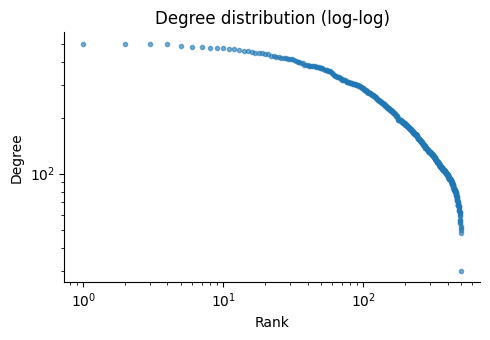

In [29]:
fig, ax = plt.subplots(figsize=(5, 3.5))
deg_seq = sorted(degrees, reverse=True)
ax.loglog(range(1, len(deg_seq)+1), deg_seq, 'o', ms=3, alpha=0.6, color='#1f77b4')
ax.set_xlabel('Rank')
ax.set_ylabel('Degree')
ax.set_title('Degree distribution (log-log)')
plt.tight_layout()
plt.savefig('fig_supp_degree.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig_supp_degree.png', dpi=150, bbox_inches='tight')
plt.show()